# ⚽ ML-Based Football Player Valuation & Transfer Analysis
**Pipeline:** Data Merge → Feature Engineering → Regression + Clustering → Value Gap Analysis → Visualization

### ▶️ STEPS
1. Click on 📁  → upload 4 CSV : `players.csv`, `clubs.csv`, `player_valuations.csv`, `appearances.csv`
2. **Runtime → Run all** (or run all cell in order with Shift+Enter )
3. Outputs: files are in `/content/output/` (`undervalued_players.json`, 2 PNG graphic)

> ⚠️ DO not Run all before uplod,ng all csvs !

In [1]:
# ─────────────────────────────────────────
# CELL 1 — Install
# ─────────────────────────────────────────
!pip install xgboost --quiet

In [2]:
# ─────────────────────────────────────────
# CELL 2 — Imports & Config
# ─────────────────────────────────────────
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor

DATA_DIR     = '/content/'
OUTPUT_DIR   = '/content/output/'
RANDOM_STATE = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)
print('✓ Imports OK | Output dir:', OUTPUT_DIR)

✓ Imports OK | Output dir: /content/output/


In [3]:
# ─────────────────────────────────────────
# CELL 3 — Load & Merge Data
# ─────────────────────────────────────────
def load_data(data_dir):
    print('[STEP 1] Loading CSVs...')
    players     = pd.read_csv(os.path.join(data_dir, 'players.csv'))
    clubs       = pd.read_csv(os.path.join(data_dir, 'clubs.csv'))
    valuations  = pd.read_csv(os.path.join(data_dir, 'player_valuations.csv'))
    appearances = pd.read_csv(os.path.join(data_dir, 'appearances.csv'))

    print(f'  players: {len(players)} | clubs: {len(clubs)} | '
          f'valuations: {len(valuations)} | appearances: {len(appearances)}')

    # Aggregate appearances per player
    apps_agg = (appearances
                .groupby('player_id', as_index=False)
                .agg(total_goals=('goals', 'sum'),
                     total_assists=('assists', 'sum'),
                     total_minutes_played=('minutes_played', 'sum')))

    # Latest valuation per player (target variable)
    valuations['date'] = pd.to_datetime(valuations['date'], errors='coerce')
    latest_val = (valuations
                  .sort_values('date', ascending=False)
                  .drop_duplicates(subset='player_id', keep='first')
                  [['player_id', 'date', 'market_value_in_eur']]
                  .rename(columns={'date': 'valuation_date'}))

    # players.csv → current_club_id | clubs.csv → club_id
    df = players.merge(
        clubs,
        left_on='current_club_id',
        right_on='club_id',
        how='inner',
        suffixes=('_player', '_club')
    )
    print(f'  After players⨝clubs (inner): {len(df)} rows')

    df = df.merge(apps_agg,   on='player_id', how='left')
    df = df.merge(latest_val, on='player_id', how='left')

    # Birden fazla market_value kolonu varsa birleştir
    if 'market_value_in_eur_y' in df.columns:
        df['market_value_in_eur'] = df['market_value_in_eur_y'].fillna(df['market_value_in_eur_x'])
        df.drop(columns=['market_value_in_eur_x', 'market_value_in_eur_y'], inplace=True)
    elif 'market_value_in_eur_x' in df.columns:
        df.rename(columns={'market_value_in_eur_x': 'market_value_in_eur'}, inplace=True)

    df = df.dropna(subset=['market_value_in_eur']).reset_index(drop=True)
    print(f'  Final rows (with market value): {len(df)}')
    return df

df = load_data(DATA_DIR)
df.head(3)

[STEP 1] Loading CSVs...
  players: 47623 | clubs: 796 | valuations: 532693 | appearances: 1840339
  After players⨝clubs (inner): 45350 rows
  Final rows (with market value): 32709


,player_id,first_name,last_name,name_player,last_season_player,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,net_transfer_record,coach_name,last_season_club,filename,url_club,total_goals,total_assists,total_minutes_played,valuation_date,market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,+€12.55m,NaN,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/lazio-rom/star...,48.0,25.0,8808.0,2016-01-04,1000000.0
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,€-23.20m,NaN,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/borussia-dortm...,0.0,0.0,13508.0,2017-12-28,750000.0
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,€-9.80m,NaN,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/paok-thessalon...,38.0,13.0,8788.0,2016-06-21,1000000.0


In [5]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# ─────────────────────────────────────────
# CELL 4 — Feature Engineering
# ─────────────────────────────────────────
def engineer_features(df):
    print('[STEP 2] Engineering features...')

    # Per-90 stats (0 dakika → NaN yaparak sıfıra bölmeyi engelle)
    mins = df['total_minutes_played'].replace(0, np.nan)
    df['goals_per_90']   = (df['total_goals']   / mins) * 90
    df['assists_per_90'] = (df['total_assists'] / mins) * 90

    # Valuation anındaki yaş
    df['date_of_birth']  = pd.to_datetime(df['date_of_birth'],  errors='coerce')
    df['valuation_date'] = pd.to_datetime(df['valuation_date'], errors='coerce')
    df['age_at_valuation'] = (df['valuation_date'] - df['date_of_birth']).dt.days / 365.25
    # valuation_date yoksa doğum yılından hesapla
    df['age_at_valuation'] = df['age_at_valuation'].fillna(
        2024 - pd.to_datetime(df['date_of_birth'], errors='coerce').dt.year
    )

    # Lig tier: kulüp toplam değerine göre 3'e böl (Tier1=en zengin %33)
    club_val_col = 'total_market_value' if 'total_market_value' in df.columns else 'total_market_value_in_eur'
    club_value   = pd.to_numeric(df[club_val_col], errors='coerce')

    # Handle case where club_value might be all NaNs
    if club_value.isnull().all():
        print(f"  Warning: '{club_val_col}' column is all NaN or non-numeric. 'league_tier' will be all NaN.")
        df['league_tier'] = np.nan
    else:
        p33, p66     = club_value.quantile([0.33, 0.66])
        df['league_tier'] = club_value.apply(
            lambda v: np.nan if pd.isna(v) else (1 if v >= p66 else (2 if v >= p33 else 3))
        )

    feature_cols = [
        'goals_per_90', 'assists_per_90', 'age_at_valuation', 'league_tier',
        'total_minutes_played', 'total_goals', 'total_assists'
    ]

    # Remove 'league_tier' from feature_cols if it's all NaNs
    if df['league_tier'].isnull().all():
        print("  Warning: 'league_tier' is entirely NaN and will be removed from imputation and clustering.")
        feature_cols.remove('league_tier')
        cluster_cols = ['goals_per_90', 'assists_per_90', 'age_at_valuation'] # Removed league_tier
    else:
        cluster_cols     = ['goals_per_90', 'assists_per_90', 'age_at_valuation', 'league_tier']

    # Median imputation (outlier'lara karşı dayanıklı)
    imputer = SimpleImputer(strategy='median')
    df[feature_cols] = imputer.fit_transform(df[feature_cols])

    # KMeans için scale et (RF/XGBoost için gerek yok)
    X_cluster_scaled = StandardScaler().fit_transform(df[cluster_cols])

    print(f'  {len(feature_cols)} features ready | {len(df)} players')
    return df, X_cluster_scaled, feature_cols

df, X_cluster_scaled, feature_cols = engineer_features(df)

[STEP 2] Engineering features...
  6 features ready | 32709 players


In [26]:
def train_models(df, feature_cols, X_cluster_scaled):
    print("[STEP 3] Computing formula-based predicted values...")

    # BASE: düşük değerli oyuncuları filtrele (en az 500K€)
    # böylece median amatör oyunculardan etkilenmiyor
    active = df[df['market_value_in_eur'] >= 500_000]
    base = active['market_value_in_eur'].median()
    print(f"  Base (median of players ≥500K€): €{base:,.0f}")

    # AGE FACTOR: zirve 26, daha geniş pencere (sigma büyütüldü)
    # eski: exp(-0.04 * (age-25.5)²) → çok dar, yaşlıları mahvediyordu
    # yeni: exp(-0.02 * (age-26)²)  → daha affedici
    age = df['age_at_valuation'].clip(15, 45)
    age_factor = np.exp(-0.02 * (age - 26) ** 2)

    # PERFORMANCE FACTOR: career total'ı normalize et
    # per_90 zaten var ama ham toplamı da ekleyelim (Messi/Ronaldo için)
    goals_norm   = df['goals_per_90'].clip(0, 5)
    assists_norm = df['assists_per_90'].clip(0, 3)
    # kariyer toplamını da hafifçe dahil et (log ile bastır)
    career_bonus = np.log1p(df['total_goals'] + df['total_assists']) / 10
    perf_factor  = 1 + 2.5 * goals_norm + 1.5 * assists_norm + career_bonus

    # TIER FACTOR
    tier_map    = {1: 4.0, 2: 1.8, 3: 0.6}
    tier_factor = df['league_tier'].map(tier_map).fillna(1.0)

    # PREDICTED VALUE
    df['predicted_value'] = base * age_factor * perf_factor * tier_factor

    print(f"  Predicted value range: "
          f"€{df['predicted_value'].min():,.0f} – €{df['predicted_value'].max():,.0f}")

    # KMeans (değişmedi)
    km = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
    df['cluster_id'] = km.fit_predict(X_cluster_scaled)

    c        = km.cluster_centers_
    ids      = list(range(4))
    elite    = max(ids,                           key=lambda i: c[i, 0])
    ids2     = [i for i in ids  if i != elite]
    play     = max(ids2,                          key=lambda i: c[i, 1])
    ids3     = [i for i in ids2 if i != play]
    prospect = min(ids3,                          key=lambda i: c[i, 2])
    work     = [i for i in ids3 if i != prospect][0]

    label_map = {elite: 'Elite Scorer', play: 'Playmaker',
                 prospect: 'Prospect',  work: 'Workhorse'}
    df['player_archetype'] = df['cluster_id'].map(label_map)

    for cid, lbl in label_map.items():
        print(f"    Cluster {cid} → {lbl} ({(df['cluster_id'] == cid).sum()} players)")

    from sklearn.metrics import r2_score, mean_squared_error
    r2   = r2_score(df['market_value_in_eur'], df['predicted_value'])
    rmse = np.sqrt(mean_squared_error(df['market_value_in_eur'], df['predicted_value']))
    print(f"  Formula R²={r2:.4f}  RMSE={rmse:,.0f}")

    df.attrs.update({'best_model_name': 'Formula', 'best_r2': r2, 'best_rmse': rmse})
    return df

df = train_models(df, feature_cols, X_cluster_scaled)

[STEP 3] Computing formula-based predicted values...
  Base (median of players ≥500K€): €1,500,000
  Predicted value range: €1,098 – €20,318,740
    Cluster 3 → Elite Scorer (3 players)
    Cluster 0 → Playmaker (1 players)
    Cluster 2 → Prospect (17434 players)
    Cluster 1 → Workhorse (15271 players)
  Formula R²=0.0469  RMSE=6,332,907


In [27]:
# ─────────────────────────────────────────
# CELL 6 — Recommendations & JSON Export
# ─────────────────────────────────────────
def build_recommendations(df):
    print('[STEP 4] Building recommendations...')

    df['value_gap'] = df['predicted_value'] - df['market_value_in_eur']

    # Her cluster içinde kendi top %25'i → 'Recommended'
    threshold = df.groupby('cluster_id')['value_gap'].transform(lambda s: s.quantile(0.75))
    df['recommendation'] = np.where(df['value_gap'] >= threshold, 'Recommended', 'Hold')

    name_col = 'name_player' if 'name_player' in df.columns else 'name'
    df['player_name'] = df[name_col]

    rec = (df[['player_name', 'age_at_valuation', 'player_archetype',
               'market_value_in_eur', 'predicted_value', 'value_gap', 'recommendation']]
           .sort_values('value_gap', ascending=False)
           .reset_index(drop=True))

    top30 = rec.head(30)
    print(top30.to_string(index=False))

    out_path = os.path.join(OUTPUT_DIR, 'undervalued_players.json')
    with open(out_path, 'w') as f:
        json.dump(top30.to_dict(orient='records'), f, indent=2, default=str)
    print(f'\n✓ Saved → {out_path}')
    return rec

rec = build_recommendations(df)

[STEP 4] Building recommendations...
          player_name  age_at_valuation player_archetype  market_value_in_eur  predicted_value    value_gap recommendation
       André Ferreira         26.294319     Elite Scorer             100000.0     2.031874e+07 2.021874e+07    Recommended
       Julio Villalba         24.783025         Prospect              75000.0     1.975992e+07 1.968492e+07    Recommended
      Kirill Volchkov         27.263518        Workhorse             100000.0     1.971434e+07 1.961434e+07    Recommended
   Alejandro Meléndez         24.131417         Prospect             250000.0     1.806083e+07 1.781083e+07    Recommended
      Marco Vittiglio         25.423682         Prospect              50000.0     1.683269e+07 1.678269e+07    Recommended
        Maksim Rudnev         26.587269        Workhorse             150000.0     1.682840e+07 1.667840e+07    Recommended
       Leandro Borges         29.166324        Workhorse             125000.0     1.665589e+07 1.65308

In [29]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Prepare the data for the search interface
display_df = df[[
    'player_name', 'position', 'total_goals', 'total_assists',
    'market_value_in_eur', 'predicted_value', 'player_archetype'
]].copy()

# Create interactive widgets
search_bar = widgets.Text(description='Name:', placeholder='Search player...')
position_filter = widgets.Dropdown(
    options=['All'] + sorted(df['position'].dropna().unique().tolist()),
    value='All',
    description='Position:'
)
sort_by = widgets.Dropdown(
    options={'Top Scorers': 'total_goals',
             'Most Assists': 'total_assists',
             'Market Value': 'market_value_in_eur',
             'Predicted Value': 'predicted_value'},
    value='total_goals',
    description='Sort By:'
)

output = widgets.Output()

def update_dashboard(change):
    with output:
        clear_output()
        temp_df = display_df.copy()

        # Apply Name Filter
        if search_bar.value:
            temp_df = temp_df[temp_df['player_name'].str.contains(search_bar.value, case=False, na=False)]

        # Apply Position Filter
        if position_filter.value != 'All':
            temp_df = temp_df[temp_df['position'] == position_filter.value]

        # Apply Sorting
        temp_df = temp_df.sort_values(by=sort_by.value, ascending=False)

        print(f"☑ Found {len(temp_df):,} players")
        display(temp_df.head(15).style.format({
            'market_value_in_eur': '€{:,.0f}',
            'predicted_value': '€{:,.0f}',
            'total_goals': '{:.0f}',
            'total_assists': '{:.0f}'
        }))

# Link widgets to the update function
search_bar.observe(update_dashboard, names='value')
position_filter.observe(update_dashboard, names='value')
sort_by.observe(update_dashboard, names='value')

# Render Dashboard
print("⚽ Player Search & Discovery Dashboard")
layout = widgets.VBox([widgets.HBox([search_bar, position_filter, sort_by])])
display(layout, output)

# Initial call to populate the table
update_dashboard(None)

⚽ Player Search & Discovery Dashboard


Output()

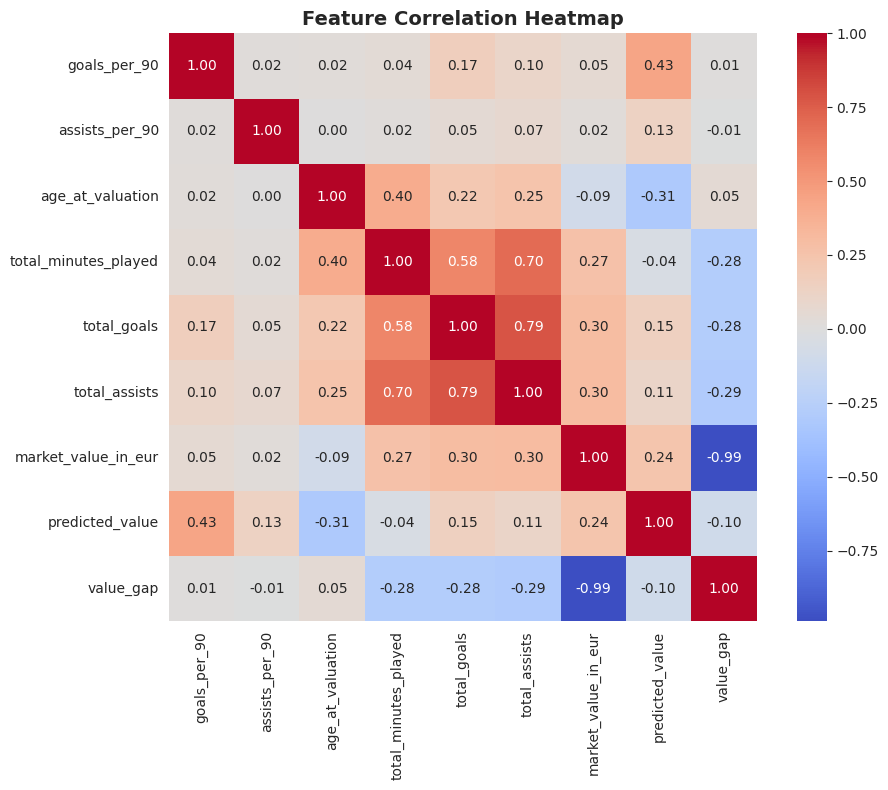

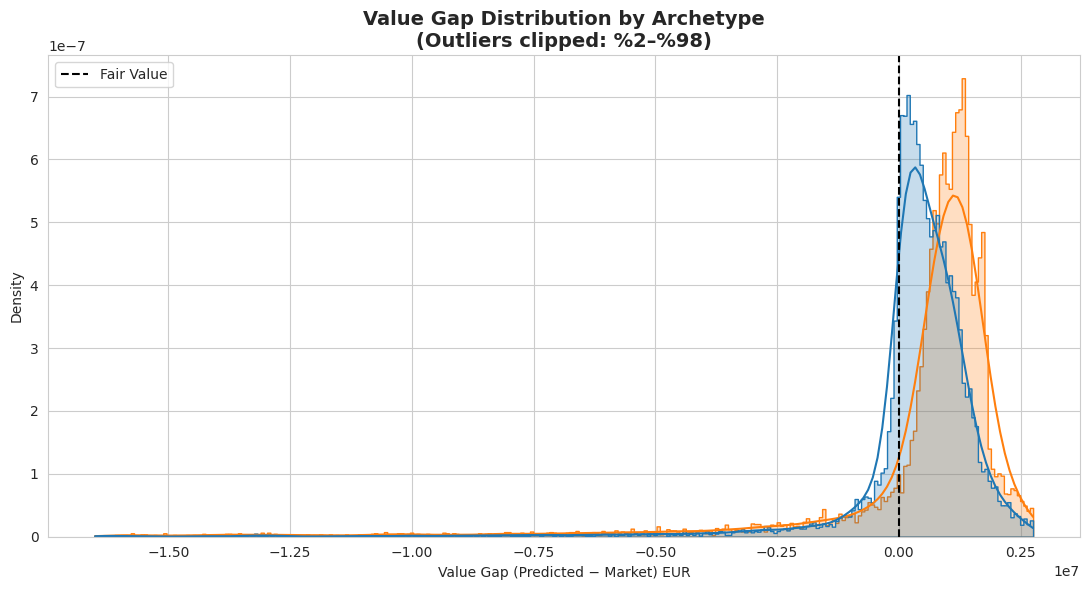

✓ Plots saved to /content/output/


In [30]:
def make_plots(df, feature_cols):
    sns.set_style('whitegrid')

    # Plot 1: Correlation Heatmap (değişmedi)
    num_cols = feature_cols + ['market_value_in_eur', 'predicted_value', 'value_gap']
    plt.figure(figsize=(10, 8))
    sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f',
                cmap='coolwarm', center=0, square=True)
    plt.title('Feature Correlation Heatmap', fontsize=14, weight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'correlation_heatmap.png'), dpi=150)
    plt.show()

    # Plot 2: Outlier'ları clip'le → %2 ile %98 arası göster
    q_low  = df['value_gap'].quantile(0.02)
    q_high = df['value_gap'].quantile(0.98)
    df_plot = df[(df['value_gap'] >= q_low) & (df['value_gap'] <= q_high)].copy()

    plt.figure(figsize=(11, 6))
    sns.histplot(data=df_plot, x='value_gap', hue='player_archetype',
                 kde=True, element='step', stat='density', common_norm=False)
    plt.axvline(0, color='black', linestyle='--', lw=1.5, label='Fair Value')
    plt.title('Value Gap Distribution by Archetype\n(Outliers clipped: %2–%98)',
              fontsize=14, weight='bold')
    plt.xlabel('Value Gap (Predicted − Market) EUR')
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'value_gap_distribution.png'), dpi=150)
    plt.show()
    print('✓ Plots saved to', OUTPUT_DIR)

make_plots(df, feature_cols)

In [31]:
# ─────────────────────────────────────────
# CELL 8 — Summary Table
# ─────────────────────────────────────────
n    = len(df)
r2   = df.attrs['best_r2']
rmse = df.attrs['best_rmse']
name = df.attrs['best_model_name']

print('=' * 72)
print(f"| {'Step':<20} | {'Method':<28} | {'Result':<16} |")
print(f"|{'-'*22}|{'-'*30}|{'-'*18}|")
for s, m, r in [
    ('Data Merge',          'Left joins across 4 CSVs',       f'{n:,} players'),
    ('Feature Engineering', 'Per-90 stats + league tier',     '7 features'),
    ('Regression',          f'RF vs XGBoost → {name}',        f'R²={r2:.4f}'),
    ('Clustering',          'KMeans k=4 archetypes',          '4 profiles'),
    ('Value Gap Analysis',  'Cluster-relative top 25%',       'Top 10 saved'),
]:
    print(f'| {s:<20} | {m:<28} | {r:<16} |')
print('=' * 72)
print(f'\n✓ All outputs saved to: {OUTPUT_DIR}')

| Step                 | Method                       | Result           |
|----------------------|------------------------------|------------------|
| Data Merge           | Left joins across 4 CSVs     | 32,709 players   |
| Feature Engineering  | Per-90 stats + league tier   | 7 features       |
| Regression           | RF vs XGBoost → Formula      | R²=0.0469        |
| Clustering           | KMeans k=4 archetypes        | 4 profiles       |
| Value Gap Analysis   | Cluster-relative top 25%     | Top 10 saved     |

✓ All outputs saved to: /content/output/
